# Task 3


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

## Load the data

In [13]:
# Task 3: load existing cluster labels (do not re-run or change Task 2 models)
stocks = pd.read_csv('task2_cluster_assignments.csv')
meta = pd.read_csv('sp500_tickers.csv')

DATA_DIR = Path('task3_results')
DATA_DIR.mkdir(exist_ok=True)

feature_cols = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
cluster_cols = ['Ward_Risk', 'KMeans_Risk', 'Ward_RFM', 'KMeans_RFM']
required_cols = ['Ticker'] + feature_cols + cluster_cols

In [14]:
# Validate and clean stocks dataset
missing_cols = [c for c in required_cols if c not in stocks.columns]
if missing_cols:
    raise ValueError(f"Missing columns in Task 2 assignments: {', '.join(missing_cols)}")

In [15]:
stocks['Ticker'] = stocks['Ticker'].astype(str).str.strip().str.replace('.', '-', regex=False)
if stocks['Ticker'].duplicated().any():
    raise ValueError('Duplicate tickers in Task 2 assignments; inspect before continuing.')

In [16]:
stocks[feature_cols + cluster_cols] = stocks[feature_cols + cluster_cols].apply(pd.to_numeric, errors='coerce')
if stocks[required_cols].isna().any().any():
    raise ValueError('Missing values in required features or cluster labels; fix Task 2 first.')

In [17]:
if (stocks['Monetary'] < 0).any():
    raise ValueError('Monetary contains negative values.')
stocks['Log_Monetary'] = np.log1p(stocks['Monetary'])

In [18]:
# Fallback for Ward_RF_Only if missing
if 'Ward_RF_Only' not in stocks.columns and 'Ward_RF' in stocks.columns:
    stocks['Ward_RF_Only'] = stocks['Ward_RF']

In [19]:
# Clean and merge metadata
symbol_col = 'Symbol' if 'Symbol' in meta.columns else 'Ticker'
if symbol_col not in meta.columns or 'GICS Sector' not in meta.columns:
    raise ValueError('Ticker file needs Symbol/Ticker and GICS Sector columns.')

meta['Ticker'] = meta[symbol_col].astype(str).str.strip().str.replace('.', '-', regex=False)
meta_cols = ['Ticker', 'GICS Sector']
if 'GICS Sub-Industry' in meta.columns:
    meta_cols.append('GICS Sub-Industry')

In [20]:
master_df = stocks.merge(meta[meta_cols].drop_duplicates('Ticker'), on='Ticker', how='left', validate='one_to_one')

missing_sectors = int(master_df['GICS Sector'].isna().sum())
print(f"Stocks in analysis: {len(master_df)}")
print(f"Missing sector labels: {missing_sectors}")
if missing_sectors:
    display(master_df.loc[master_df['GICS Sector'].isna(), ['Ticker']])

master_df['GICS Sector'] = master_df['GICS Sector'].fillna('Unknown')
display(master_df[['Ticker', *feature_cols, 'GICS Sector', *cluster_cols]].head())

Stocks in analysis: 498
Missing sector labels: 0


,Ticker,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary,GICS Sector,Ward_Risk,KMeans_Risk,Ward_RFM,KMeans_RFM
0,A,0.001121,1.074723,11,2,1.400180e+10,Health Care,0,0,0,1
1,AAPL,0.003930,1.174836,11,2,6.233034e+11,Information Technology,0,1,0,1
2,ABBV,0.003749,0.425366,11,3,6.837054e+10,Health Care,1,0,0,1
3,ABNB,0.001475,1.472709,11,3,3.652850e+10,Consumer Discretionary,0,1,0,1
4,ABT,0.000971,0.583543,11,1,3.523027e+10,Health Care,1,0,0,1


## 3.2.1 - Compare cluster assignments

In [21]:
# 3.2.1: compare Risk-Return clusters against RFM clusters on the SAME stocks
comparison_rows = []
for name, risk_col, rfm_col in [
    ('Ward', 'Ward_Risk', 'Ward_RFM'),
    ('K-Means', 'KMeans_Risk', 'KMeans_RFM'),
]:
    ari = adjusted_rand_score(master_df[risk_col], master_df[rfm_col])
    comparison_rows.append({'Algorithm': name, 'Risk_Cluster_Count': master_df[risk_col].nunique(),
                            'RFM_Cluster_Count': master_df[rfm_col].nunique(), 'ARI': ari})
    ct = pd.crosstab(master_df[risk_col], master_df[rfm_col], margins=True)
    print(f'\n{name}: Risk-Return vs RFM; ARI = {ari:.4f}')
    display(ct)
    ct.to_csv(DATA_DIR / f'task3_{name.lower().replace("-", "")}_risk_vs_rfm.csv')

cross_paradigm_summary = pd.DataFrame(comparison_rows)
display(cross_paradigm_summary)
cross_paradigm_summary.to_csv(DATA_DIR / 'task3_cross_paradigm_ari.csv', index=False)


Ward: Risk-Return vs RFM; ARI = 0.0130


Ward_RFM,0,1,All
Ward_Risk,,,
0,257,56,313
1,142,35,177
2,5,3,8
All,404,94,498



K-Means: Risk-Return vs RFM; ARI = 0.0250


KMeans_RFM,0,1,All
KMeans_Risk,,,
0,46,305,351
1,26,121,147
All,72,426,498


,Algorithm,Risk_Cluster_Count,RFM_Cluster_Count,ARI
0,Ward,3,2,0.012981
1,K-Means,2,2,0.024968


## Cluster profiles in original units

In [22]:
# 3.2.1: cluster profiles in original units (not standardized data)
profile_cols = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
all_profiles = []
for cluster_col in cluster_cols:
    table = master_df.groupby(cluster_col).agg(
        Ticker_Count=('Ticker', 'size'),
        Mean_Weekly_Return=('Mean_Weekly_Return', 'mean'),
        Weekly_Beta=('Weekly_Beta', 'mean'),
        Recency_Days=('Recency', 'mean'),
        Frequency_Days=('Frequency', 'mean'),
        Traded_Value_USD=('Monetary', 'mean')
    ).reset_index().rename(columns={cluster_col: 'Cluster'})
    table.insert(0, 'Solution', cluster_col)
    all_profiles.append(table)
    print(f'\n{cluster_col} original-unit profiles:')
    display(table.round(4))

profiles_df = pd.concat(all_profiles, ignore_index=True)
profiles_df.to_csv(DATA_DIR / 'task3_cluster_profiles.csv', index=False)


Ward_Risk original-unit profiles:


,Solution,Cluster,Ticker_Count,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency_Days,Traded_Value_USD
0,Ward_Risk,0,313,0.0032,1.1780,19.1693,3.0288,4.197537e+10
1,Ward_Risk,1,177,0.0021,0.5789,21.3051,2.9435,2.311690e+10
2,Ward_Risk,2,8,0.0174,2.3692,55.3750,3.3750,3.121938e+11



KMeans_Risk original-unit profiles:


,Solution,Cluster,Ticker_Count,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency_Days,Traded_Value_USD
0,KMeans_Risk,0,351,0.0020,0.7986,19.1481,2.9231,2.229362e+10
1,KMeans_Risk,1,147,0.0054,1.4274,23.7619,3.1973,8.096921e+10



Ward_RFM original-unit profiles:


,Solution,Cluster,Ticker_Count,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency_Days,Traded_Value_USD
0,Ward_RFM,0,404,0.0030,0.9761,12.3614,3.2203,3.820898e+10
1,Ward_RFM,1,94,0.0031,1.0189,55.5319,2.0745,4.565006e+10



KMeans_RFM original-unit profiles:


,Solution,Cluster,Ticker_Count,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency_Days,Traded_Value_USD
0,KMeans_RFM,0,72,0.0033,1.0267,62.4861,1.8472,8.060058e+10
1,KMeans_RFM,1,426,0.0030,0.9770,13.4155,3.1995,3.268613e+10


## Sector composition

In [23]:
# 3.2.1: sector counts and percentages inside each cluster
sector_names = sorted(master_df['GICS Sector'].unique())
sector_pct = {}
for cluster_col in cluster_cols:
    counts = pd.crosstab(master_df[cluster_col], master_df['GICS Sector']).reindex(columns=sector_names, fill_value=0)
    percentages = pd.crosstab(master_df[cluster_col], master_df['GICS Sector'], normalize='index').reindex(columns=sector_names, fill_value=0).mul(100)
    sector_pct[cluster_col] = percentages
    print(f'\n{cluster_col} sector counts:')
    display(counts)
    print(f'{cluster_col} sector percentage of cluster (%):')
    display(percentages.round(1))
    counts.to_csv(DATA_DIR / f'task3_{cluster_col}_sector_counts.csv')
    percentages.to_csv(DATA_DIR / f'task3_{cluster_col}_sector_percentages.csv')


Ward_Risk sector counts:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk,,,,,,,,,,,
0,11,39,4,11,52,29,61,68,15,19,4
1,9,7,28,10,23,31,18,4,9,11,27
2,2,1,0,0,1,0,2,2,0,0,0


Ward_Risk sector percentage of cluster (%):


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk,,,,,,,,,,,
0,3.5,12.5,1.3,3.5,16.6,9.3,19.5,21.7,4.8,6.1,1.3
1,5.1,4.0,15.8,5.6,13.0,17.5,10.2,2.3,5.1,6.2,15.3
2,25.0,12.5,0.0,0.0,12.5,0.0,25.0,25.0,0.0,0.0,0.0



KMeans_Risk sector counts:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Risk,,,,,,,,,,,
0,15,26,31,16,56,58,53,22,19,27,28
1,7,21,1,5,20,2,28,52,5,3,3


... (6 outputs left out)


KMeans_RFM sector counts:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
0,2,8,5,1,12,8,5,15,6,0,10
1,20,39,27,20,64,52,76,59,18,30,21


KMeans_RFM sector percentage of cluster (%):


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
0,2.8,11.1,6.9,1.4,16.7,11.1,6.9,20.8,8.3,0.0,13.9
1,4.7,9.2,6.3,4.7,15.0,12.2,17.8,13.8,4.2,7.0,4.9


## Sector charts

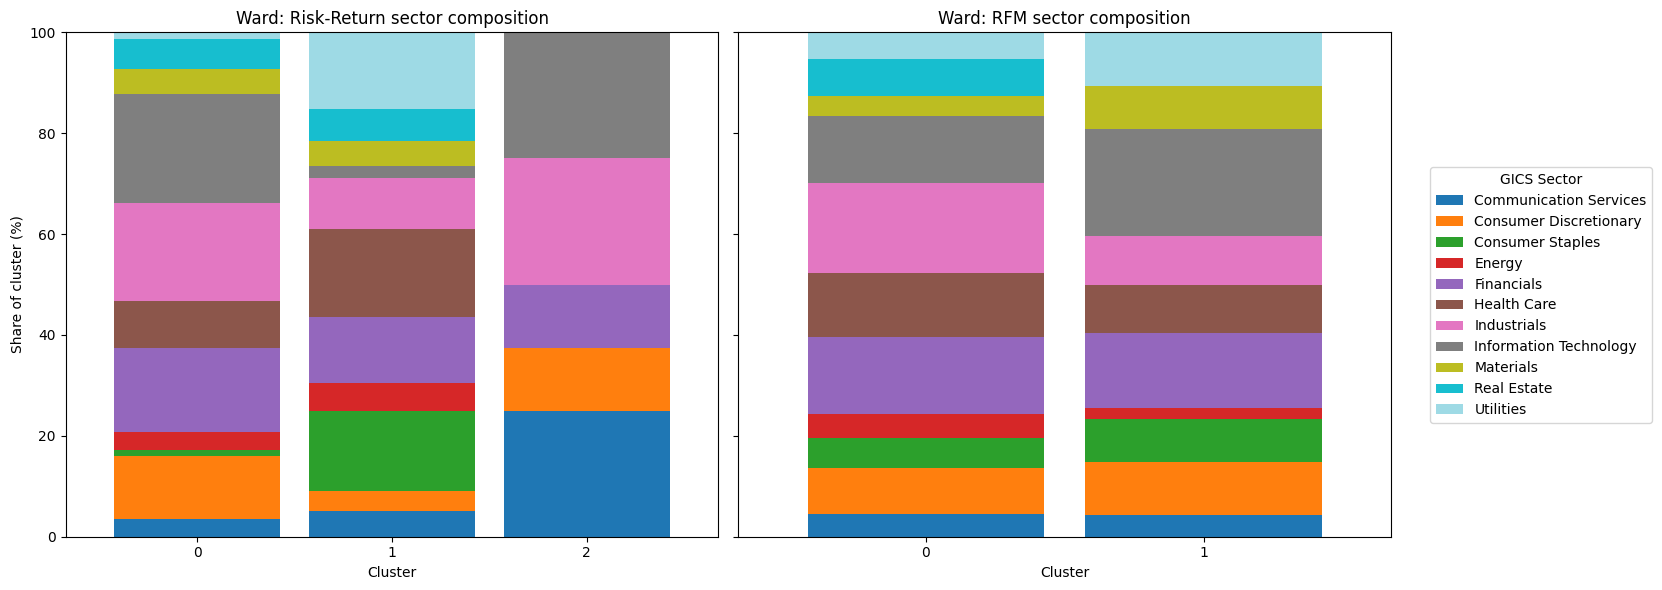

In [24]:
# 3.2.1: side-by-side sector composition charts
# Draw as separate figures, so both remain readable in the report.
for algorithm, risk_col, rfm_col in [('Ward', 'Ward_Risk', 'Ward_RFM')]:
    fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
    for ax, label_col, label_title in [
        (axes[0], risk_col, 'Risk-Return'),
        (axes[1], rfm_col, 'RFM'),
    ]:
        sector_pct[label_col].plot(kind='bar', stacked=True, ax=ax, legend=False, colormap='tab20', width=0.85)
        ax.set_title(f'{algorithm}: {label_title} sector composition')
        ax.set_xlabel('Cluster')
        ax.set_ylabel('Share of cluster (%)')
        ax.set_ylim(0, 100)
        ax.tick_params(axis='x', rotation=0)
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, title='GICS Sector', loc='center left', bbox_to_anchor=(0.84, 0.5))
    fig.tight_layout(rect=(0, 0, 0.83, 1))
    fig.savefig(DATA_DIR / f'task3_{algorithm.lower()}_sector_comparison.png', dpi=180, bbox_inches='tight')
    plt.show()

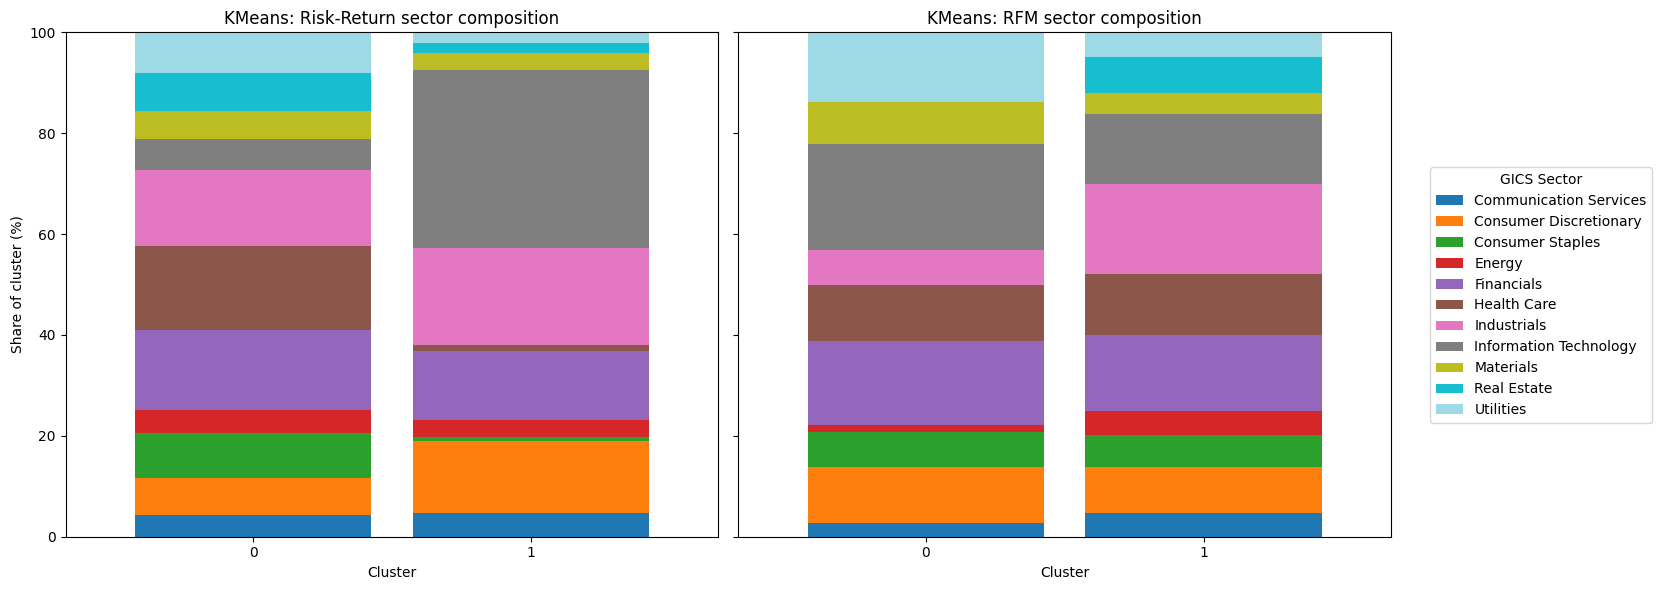

In [25]:
# 3.2.1: side-by-side sector composition charts
# Draw as separate figures, so both remain readable in the report.
for algorithm, risk_col, rfm_col in [('KMeans', 'KMeans_Risk', 'KMeans_RFM')]:
    fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
    for ax, label_col, label_title in [
        (axes[0], risk_col, 'Risk-Return'),
        (axes[1], rfm_col, 'RFM'),
    ]:
        sector_pct[label_col].plot(kind='bar', stacked=True, ax=ax, legend=False, colormap='tab20', width=0.85)
        ax.set_title(f'{algorithm}: {label_title} sector composition')
        ax.set_xlabel('Cluster')
        ax.set_ylabel('Share of cluster (%)')
        ax.set_ylim(0, 100)
        ax.tick_params(axis='x', rotation=0)
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, title='GICS Sector', loc='center left', bbox_to_anchor=(0.84, 0.5))
    fig.tight_layout(rect=(0, 0, 0.83, 1))
    fig.savefig(DATA_DIR / f'task3_{algorithm.lower()}_sector_comparison.png', dpi=180, bbox_inches='tight')
    plt.show()

## Representative stocks

In [26]:
# 3.2.1: examples of typical stocks in each Ward cluster (data-based, not news claims)
examples = []
for label_col, cols in [
    ('Ward_Risk', ['Mean_Weekly_Return', 'Weekly_Beta']),
    ('Ward_RFM', ['Recency', 'Frequency', 'Log_Monetary']),
]:
    standardised = StandardScaler().fit_transform(master_df[cols])
    for group in sorted(master_df[label_col].unique()):
        positions = np.flatnonzero(master_df[label_col].to_numpy() == group)
        center = standardised[positions].mean(axis=0)
        distance = np.linalg.norm(standardised[positions] - center, axis=1)
        best_positions = positions[np.argsort(distance)[:3]]
        for pos in best_positions:
            examples.append({'Solution': label_col, 'Cluster': int(group),
                             'Ticker': master_df.iloc[pos]['Ticker'],
                             'GICS Sector': master_df.iloc[pos]['GICS Sector']})

example_stocks = pd.DataFrame(examples)
print('Representative stocks nearest each cluster centre:')
display(example_stocks)
example_stocks.to_csv(DATA_DIR / 'task3_representative_stocks.csv', index=False)

Representative stocks nearest each cluster centre:


,Solution,Cluster,Ticker,GICS Sector
0,Ward_Risk,0,DAL,Industrials
1,Ward_Risk,0,MCO,Financials
2,Ward_Risk,0,STT,Financials
3,Ward_Risk,1,EXC,Utilities
4,Ward_Risk,1,MCD,Consumer Discretionary
5,Ward_Risk,1,PPL,Utilities
6,Ward_Risk,2,APP,Communication Services
7,Ward_Risk,2,NVDA,Information Technology
8,Ward_Risk,2,SMCI,Information Technology
9,Ward_RFM,0,NUE,Materials


## 3.2.2 - Correlation analysis

In [27]:
# 3.2.2: RFM correlations, controlled RF-only sensitivity, and traded-value profiles
rfm_correlations = master_df[['Recency', 'Frequency', 'Log_Monetary']].corr()
print('Correlations (R, F and log1p(M)):')
display(rfm_correlations.round(3))
rfm_correlations.to_csv(DATA_DIR / 'task3_rfm_correlations.csv')

Correlations (R, F and log1p(M)):


,Recency,Frequency,Log_Monetary
Recency,1.000,-0.340,0.165
Frequency,-0.340,1.000,0.022
Log_Monetary,0.165,0.022,1.000


## Monetary removal sensitivity

In [28]:
sensitivity_ari = None

if 'Ward_RF_Only' not in master_df or master_df['Ward_RF_Only'].isna().any():
    print('WARNING: Ward_RF_Only was not exported by Task 2. Complete Task 2.5 later.')
else:
    original_k = master_df['Ward_RFM'].nunique()
    reduced_k = master_df['Ward_RF_Only'].nunique()
    if original_k != reduced_k:
        print(f'WARNING: Task 2 inconsistency: Ward_RFM has {original_k} clusters, '
              f'but Ward_RF_Only has {reduced_k}. Fix Task 2.5 before interpreting this sensitivity test.')
    else:
        sensitivity_ari = adjusted_rand_score(master_df['Ward_RFM'], master_df['Ward_RF_Only'])
        print(f'Ward RFM vs RF-only ARI (k={original_k}): {sensitivity_ari:.4f}')
        membership = pd.crosstab(master_df['Ward_RFM'], master_df['Ward_RF_Only'], margins=True)
        display(membership)
        membership.to_csv(DATA_DIR / 'task3_rfm_vs_rf_only_membership.csv')
        for label_col in ('Ward_RFM', 'Ward_RF_Only'):
            traded = master_df.groupby(label_col)['Monetary'].agg(['count', 'mean', 'median'])
            print(f'Approximate 60-session traded value (USD), grouped by {label_col}:')
            display(traded.round(2))
            traded.to_csv(DATA_DIR / f'task3_{label_col}_traded_value.csv')

Ward RFM vs RF-only ARI (k=2): 0.9531


Ward_RF_Only,0,1,All
Ward_RFM,,,
0,402,2,404
1,3,91,94
All,405,93,498


Approximate 60-session traded value (USD), grouped by Ward_RFM:


,count,mean,median
Ward_RFM,,,
0,404,3.820898e+10,1.547309e+10
1,94,4.565006e+10,2.095020e+10


Approximate 60-session traded value (USD), grouped by Ward_RF_Only:


,count,mean,median
Ward_RF_Only,,,
0,405,3.768854e+10,1.545679e+10
1,93,4.799647e+10,2.105259e+10


## Save results

In [29]:
# Task 3: save final master dataset and provenance record
expected_export_cols = ['Ticker', 'GICS Sector', *feature_cols, 'Log_Monetary', *cluster_cols]
if 'Ward_RF_Only' not in master_df:
    master_df['Ward_RF_Only'] = pd.NA  # Missing Task 2 result, not an estimated label
export_cols = expected_export_cols + ['Ward_RF_Only']
if 'GICS Sub-Industry' in master_df:
    export_cols.append('GICS Sub-Industry')
if 'Aligned_Weekly_Observations' in master_df:
    export_cols.append('Aligned_Weekly_Observations')

master_export = DATA_DIR / 'task3_master_clusters.csv'
master_df[export_cols].to_csv(master_export, index=False)

In [30]:
# Basic information about the files used
from datetime import datetime
import json

run_record = {
    'run_date': datetime.now().strftime('%Y-%m-%d'),
    'task2_file': 'task2_cluster_assignments.csv',
    'ticker_file': 'sp500_tickers.csv',
    'study_start': '2021-01-01',
    'study_end_exclusive': '2025-01-01',
    'number_of_stocks': len(master_df),
    'missing_sector_labels': missing_sectors,
    'ward_risk_rfm_ari': comparison_rows[0]['ARI'],
    'kmeans_risk_rfm_ari': comparison_rows[1]['ARI'],
    'rf_only_sensitivity_ari': sensitivity_ari
}

with open(DATA_DIR / 'task3_run_metadata.json', 'w') as f:
    json.dump(run_record, f, indent=2)

print('Saved results in:', DATA_DIR)

Saved results in: task3_results
